# MSCS 634 – Lab 4: Regression Analysis and Regularization
**Student:** Rajasekhar Reddy Kayyam  
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**Lab:** Regression Techniques and Regularization  
**Dataset:** Scikit-learn Diabetes Dataset

## Objectives
Explore the diabetes dataset, implement simple, multiple, and polynomial regression, compare Ridge and Lasso regularization, and evaluate models using MAE, MSE, RMSE, and R². The target is a quantitative measure of disease progression one year after baseline. This exercise is educational and is not a clinical prediction system.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
plt.style.use("default")
results = []

def evaluate(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    metrics = {"Model": name,
               "Train R²": r2_score(y_train, train_pred),
               "MAE": mean_absolute_error(y_test, test_pred),
               "MSE": mean_squared_error(y_test, test_pred),
               "RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
               "Test R²": r2_score(y_test, test_pred)}
    results.append(metrics)
    print(pd.Series(metrics).to_string())
    return model, test_pred


## Step 1 – Data preparation and exploration
Load all ten baseline features and inspect missing values, descriptive statistics, target distribution, and correlations. The built-in dataset is already numeric and contains no missing entries; this is verified below.

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()
print("Feature names:", list(X.columns))
print("Shape:", X.shape, "Target shape:", y.shape)
display(X.head())
display(X.describe().T)
print("Missing feature values:", X.isna().sum().sum())
print("Missing target values:", y.isna().sum())
print("Target summary:\n", y.describe())


Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Shape: (442, 10) Target shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


Missing feature values: 0
Missing target values: 0
Target summary:
 count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64


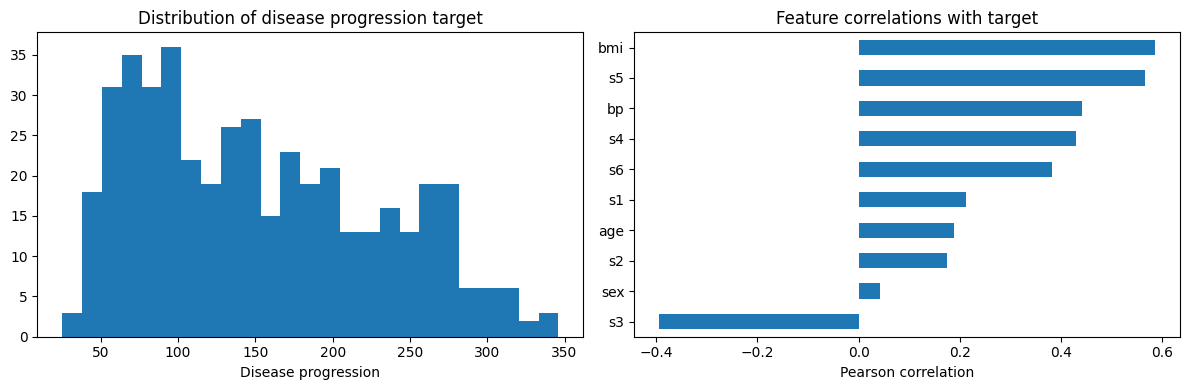

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=25)
axes[0].set_title("Distribution of disease progression target")
axes[0].set_xlabel("Disease progression")
correlations = X.assign(target=y).corr()["target"].drop("target").sort_values()
correlations.plot.barh(ax=axes[1])
axes[1].set_title("Feature correlations with target")
axes[1].set_xlabel("Pearson correlation")
plt.tight_layout(); plt.show()


### Shared train/test split
Use an 80/20 split with a fixed random seed. All models use the same held-out observations. The simple and univariate polynomial models use `bmi`; multivariate models use all ten features. Because the models use different feature sets, their results demonstrate both model complexity and added predictor information.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training: {len(X_train)} rows | Testing: {len(X_test)} rows")


Training: 353 rows | Testing: 89 rows


## Step 2 – Simple linear regression
Use only BMI as the predictor and plot the fitted line against test observations.

Model       Simple Linear (BMI)
Train R²               0.365724
MAE                   52.259976
MSE                 4061.825928
RMSE                  63.732456
Test R²                 0.23335


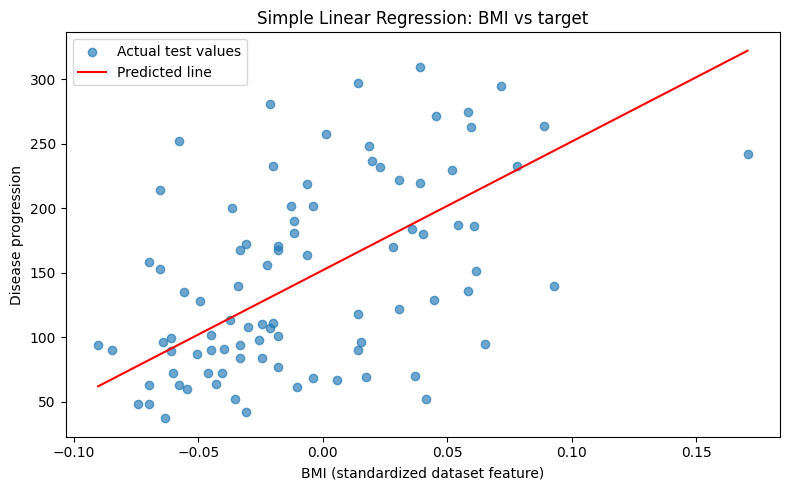

In [6]:
simple, pred_simple = evaluate("Simple Linear (BMI)", LinearRegression(),
                               X_train[["bmi"]], X_test[["bmi"]], y_train, y_test)
order = np.argsort(X_test["bmi"].to_numpy())
plt.figure(figsize=(8, 5))
plt.scatter(X_test["bmi"], y_test, alpha=0.65, label="Actual test values")
plt.plot(X_test["bmi"].to_numpy()[order], pred_simple[order], color="red", label="Predicted line")
plt.xlabel("BMI (standardized dataset feature)"); plt.ylabel("Disease progression")
plt.title("Simple Linear Regression: BMI vs target")
plt.legend(); plt.tight_layout(); plt.show()


## Step 3 – Multiple linear regression
Fit a linear model using all ten predictors, then compare actual versus predicted test values.

Model       Multiple Linear (10 features)
Train R²                         0.527919
MAE                             42.794095
MSE                           2900.193628
RMSE                            53.853446
Test R²                          0.452603


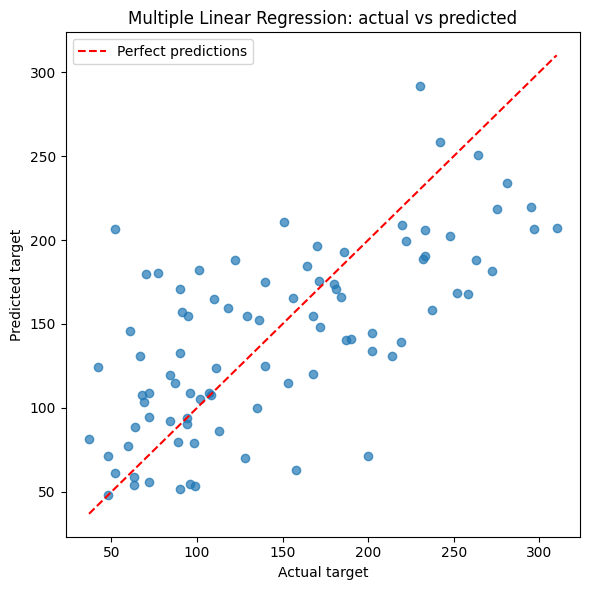

In [7]:
multiple, pred_multiple = evaluate("Multiple Linear (10 features)", LinearRegression(),
                                   X_train, X_test, y_train, y_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_multiple, alpha=0.7)
lims = [min(y_test.min(), pred_multiple.min()), max(y_test.max(), pred_multiple.max())]
plt.plot(lims, lims, "r--", label="Perfect predictions")
plt.xlabel("Actual target"); plt.ylabel("Predicted target")
plt.title("Multiple Linear Regression: actual vs predicted")
plt.legend(); plt.tight_layout(); plt.show()


## Step 4 – Polynomial regression and model complexity
Fit polynomial degrees 1, 2, 3, 5, and 10 to BMI alone. The train/test R² gap helps illustrate overfitting; low scores on both sets suggest underfitting. High-degree fits may be numerically unstable and are intentionally included for demonstration.

Model       Polynomial BMI (degree 1)
Train R²                     0.365724
MAE                         52.259976
MSE                       4061.825928
RMSE                        63.732456
Test R²                       0.23335
Model       Polynomial BMI (degree 2)
Train R²                     0.366511
MAE                         52.383912
MSE                       4085.025481
RMSE                        63.914204
Test R²                      0.228972
Model       Polynomial BMI (degree 3)
Train R²                     0.366656
MAE                           52.1814
MSE                       4064.443384
RMSE                        63.752987
Test R²                      0.232856
Model       Polynomial BMI (degree 5)
Train R²                     0.370719
MAE                         51.884611
MSE                       4085.845567
RMSE                        63.920619
Test R²                      0.228817
Model       Polynomial BMI (degree 10)
Train R²                      0.387036
MAE       

,Degree,Train R²,Test R²
0,1,0.365724,0.233350
1,2,0.366511,0.228972
2,3,0.366656,0.232856
3,5,0.370719,0.228817
4,10,0.387036,0.185464


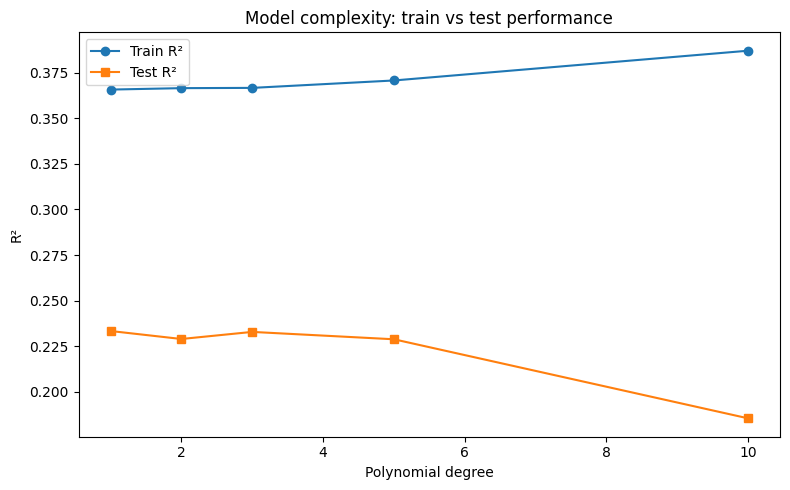

In [8]:
poly_records = []
poly_models = {}
for degree in [1, 2, 3, 5, 10]:
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                          StandardScaler(), LinearRegression())
    model, pred = evaluate(f"Polynomial BMI (degree {degree})", model,
                           X_train[["bmi"]], X_test[["bmi"]], y_train, y_test)
    poly_models[degree] = model
    poly_records.append({"Degree": degree,
                         "Train R²": r2_score(y_train, model.predict(X_train[["bmi"]])),
                         "Test R²": r2_score(y_test, pred)})
poly_df = pd.DataFrame(poly_records)
display(poly_df)
plt.figure(figsize=(8, 5))
plt.plot(poly_df["Degree"], poly_df["Train R²"], "o-", label="Train R²")
plt.plot(poly_df["Degree"], poly_df["Test R²"], "s-", label="Test R²")
plt.xlabel("Polynomial degree"); plt.ylabel("R²")
plt.title("Model complexity: train vs test performance")
plt.legend(); plt.tight_layout(); plt.show()


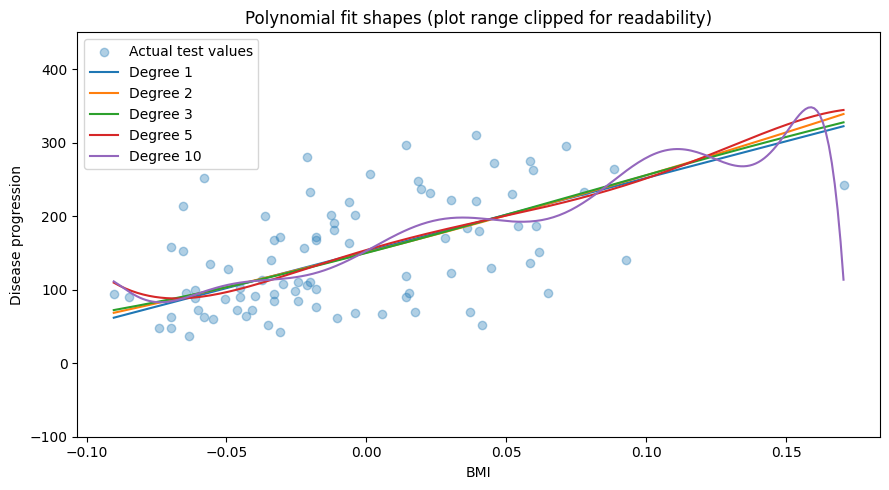

In [8]:
grid = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 250)})
plt.figure(figsize=(9, 5))
plt.scatter(X_test["bmi"], y_test, alpha=0.35, label="Actual test values")
for degree in [1, 2, 3, 5, 10]:
    plt.plot(grid["bmi"], poly_models[degree].predict(grid), label=f"Degree {degree}")
plt.ylim(-100, 450)
plt.xlabel("BMI"); plt.ylabel("Disease progression")
plt.title("Polynomial fit shapes (plot range clipped for readability)")
plt.legend(); plt.tight_layout(); plt.show()


## Step 5 – Ridge and Lasso regularization
Both models use all ten predictors. `alpha` controls the penalty: higher alpha shrinks coefficients more strongly. Ridge uses an L2 penalty and generally retains all features; Lasso uses an L1 penalty and can set coefficients exactly to zero. Scalers are fit only on training data via pipelines to avoid leakage.

Model       Ridge (alpha=1.0)
Train R²             0.527632
MAE                 42.811999
MSE               2892.014566
RMSE                53.777454
Test R²              0.454147
Model       Lasso (alpha=1.0)
Train R²             0.522543
MAE                 42.802984
MSE               2824.568094
RMSE                53.146666
Test R²              0.466877


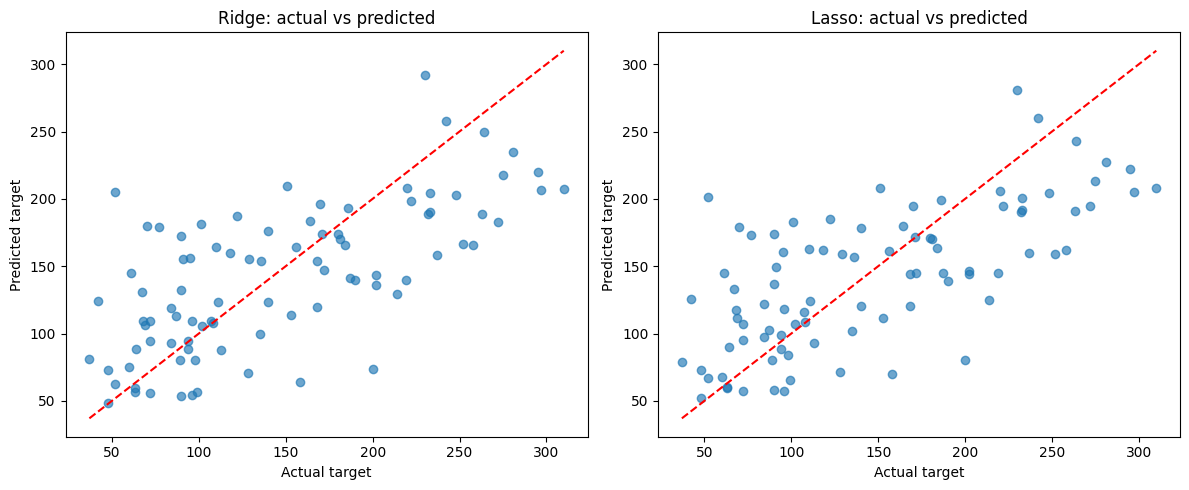

In [9]:
ridge, pred_ridge = evaluate("Ridge (alpha=1.0)",
    make_pipeline(StandardScaler(), Ridge(alpha=1.0)), X_train, X_test, y_train, y_test)
lasso, pred_lasso = evaluate("Lasso (alpha=1.0)",
    make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=20000)),
    X_train, X_test, y_train, y_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, [("Ridge", pred_ridge), ("Lasso", pred_lasso)]):
    ax.scatter(y_test, pred, alpha=0.65)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, "r--")
    ax.set_title(f"{name}: actual vs predicted")
    ax.set_xlabel("Actual target"); ax.set_ylabel("Predicted target")
plt.tight_layout(); plt.show()


,Method,Alpha,Test RMSE,Test R²,Zero coefficients
0,Ridge,0.01,53.852346,0.452625,0
1,Lasso,0.01,53.836493,0.452947,0
2,Ridge,0.10,53.842869,0.452818,0
3,Lasso,0.10,53.708698,0.455541,0
4,Ridge,1.00,53.777454,0.454147,0
5,Lasso,1.00,53.146666,0.466877,1
6,Ridge,10.00,53.626288,0.457211,0
7,Lasso,10.00,54.164885,0.446253,6
8,Ridge,100.00,53.462363,0.460524,0
9,Lasso,100.00,73.222493,-0.011963,10


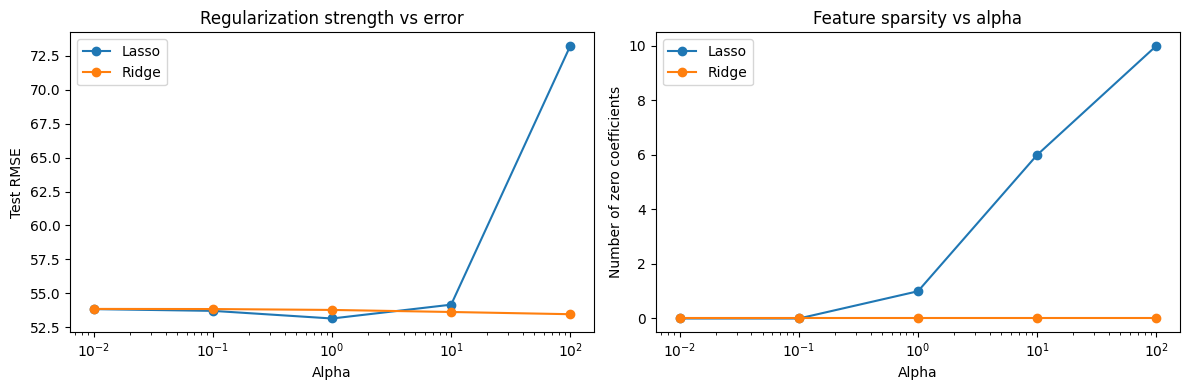

In [10]:
alpha_rows = []
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    for method in ["Ridge", "Lasso"]:
        estimator = Ridge(alpha=alpha) if method == "Ridge" else Lasso(alpha=alpha, max_iter=50000)
        pipe = make_pipeline(StandardScaler(), estimator)
        pipe.fit(X_train, y_train)
        prediction = pipe.predict(X_test)
        coef = pipe.named_steps[method.lower()].coef_
        alpha_rows.append({"Method": method, "Alpha": alpha,
                           "Test RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
                           "Test R²": r2_score(y_test, prediction),
                           "Zero coefficients": int(np.sum(np.isclose(coef, 0, atol=1e-8)))})
alpha_df = pd.DataFrame(alpha_rows)
display(alpha_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method, group in alpha_df.groupby("Method"):
    axes[0].plot(group["Alpha"], group["Test RMSE"], marker="o", label=method)
    axes[1].plot(group["Alpha"], group["Zero coefficients"], marker="o", label=method)
for ax in axes: ax.set_xscale("log"); ax.set_xlabel("Alpha"); ax.legend()
axes[0].set_ylabel("Test RMSE"); axes[0].set_title("Regularization strength vs error")
axes[1].set_ylabel("Number of zero coefficients"); axes[1].set_title("Feature sparsity vs alpha")
plt.tight_layout(); plt.show()


**Interpretation:** Small alpha values usually resemble ordinary least squares; larger values impose stronger shrinkage, potentially reducing variance but increasing bias. An excessively large alpha may underfit. The alpha sweep is illustrative rather than a tuned model selection procedure: choosing alpha from test performance would leak test information into model selection. For a final deployed model, tune alpha with cross-validation on the training set, then evaluate once on the test set.

## Step 6 – Model comparison and analysis
The table contains all requested metrics on the identical test partition. Lower MAE/MSE/RMSE and higher test R² indicate better test performance. Training R² is shown to help identify potential overfitting.

,Model,Train R²,MAE,MSE,RMSE,Test R²
0,Lasso (alpha=1.0),0.523,42.803,2824.568,53.147,0.467
1,Ridge (alpha=1.0),0.528,42.812,2892.015,53.777,0.454
2,Multiple Linear (10 features),0.528,42.794,2900.194,53.853,0.453
3,Polynomial BMI (degree 1),0.366,52.260,4061.826,63.732,0.233
4,Simple Linear (BMI),0.366,52.260,4061.826,63.732,0.233
5,Polynomial BMI (degree 3),0.367,52.181,4064.443,63.753,0.233
6,Polynomial BMI (degree 2),0.367,52.384,4085.025,63.914,0.229
7,Polynomial BMI (degree 5),0.371,51.885,4085.846,63.921,0.229
8,Polynomial BMI (degree 10),0.387,52.959,4315.533,65.693,0.185


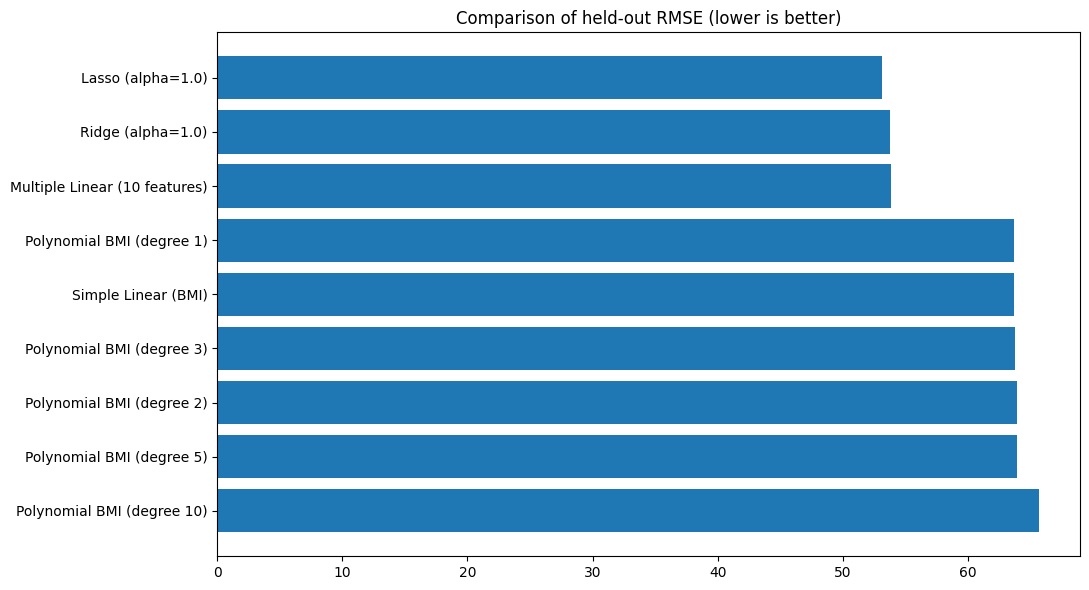

Lowest test RMSE: Lasso (alpha=1.0)
Best test R²: Lasso (alpha=1.0)


In [11]:
comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(comparison.round(3))
plt.figure(figsize=(11, 6))
plt.barh(comparison["Model"], comparison["RMSE"])
plt.gca().invert_yaxis()
plt.title("Comparison of held-out RMSE (lower is better)")
plt.tight_layout(); plt.show()
print("Lowest test RMSE:", comparison.iloc[0]["Model"])
print("Best test R²:", comparison.sort_values("Test R²", ascending=False).iloc[0]["Model"])


In [1]:
best = comparison.iloc[0]
poly_gap = poly_df.assign(gap=poly_df["Train R²"] - poly_df["Test R²"])
print(f"Best held-out RMSE: {best['Model']} ({best['RMSE']:.2f}).")
print(f"Its held-out R²: {best['Test R²']:.3f}.")
print("Largest polynomial train–test R² gap at degree:", int(poly_gap.loc[poly_gap['gap'].idxmax(), 'Degree']))
print("Lasso zero coefficients at alpha=1:", int(np.sum(np.isclose(lasso.named_steps['lasso'].coef_, 0))))


NameError: name 'comparison' is not defined

### Discussion and conclusions
- **Simple vs multiple regression:** The single-feature BMI model captures some signal, while the multiple-feature model can use additional measurements to explain variation. Compare their held-out R² and RMSE above.
- **Polynomial models:** Low degrees may miss nonlinear structure (underfitting). Higher degrees can fit the training data increasingly well but generalize worse, especially on a small dataset. The train/test comparison shows this directly.
- **Ridge vs Lasso:** Ridge shrinks coefficients smoothly, whereas Lasso can remove features entirely. Neither is guaranteed to outperform unregularized regression on every split; the measured results determine which performed better here.
- **Dataset insight:** BMI and other baseline variables have associations with disease progression, but correlation does not establish causality. The dataset is small (442 observations), so results are sensitive to split and model complexity.
- **Limitations:** This is a single random train/test split; stronger estimates require cross-validation and external validation. These models are not appropriate for medical decisions.

**Challenges/decisions:** Used a common split for consistency, a pipeline for leakage-free scaling, and multiple polynomial degrees to illustrate bias–variance tradeoffs. The alpha sweep demonstrates regularization effects but is not used to claim an optimally tuned alpha.